<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🧰 `deepagents` 0.7 的 harness：参数、middleware 栈、HITL、skills、memory、MCP

**一句话定位**：`create_deep_agent` = `create_agent` + **一叠 middleware**。你学过的三件武器（TODO / 文件 / 子 agent）各是其中一层；新课多出的 HITL、skills、memory、MCP、summarization 也都只是**参数或一层 middleware**。
> 本机 deepagents 0.7.28 源码核对；新课 m1.4–1.8、m3。

</div>

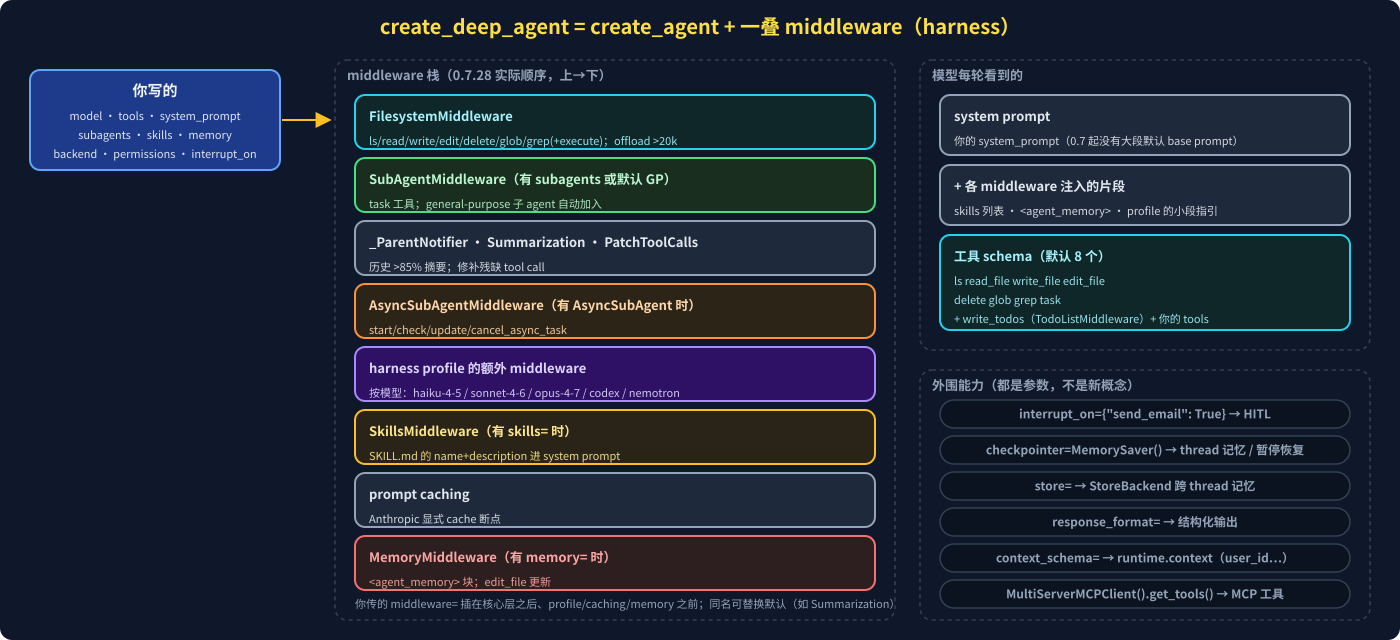

In [ ]:
from IPython.display import SVG
SVG(filename="assets/05_harness.svg")

### 1️⃣ `create_deep_agent` 参数表（0.7.28 签名）

| 参数 | 作用 | 备注 |
|---|---|---|
| `model` | `"provider:model"` 或对象 | `None` 已弃用（1.0 删除） |
| `tools` | **追加**到内置工具面 | 不会替换 `ls/read_file/...` |
| `system_prompt` | 你的指令 | 0.7 起**没有大段默认 base prompt**；不传则模型只看到工具 schema（实测 system 为空串） |
| `middleware` | 追加 / 覆盖（同名替换默认，如 `SummarizationMiddleware`） | `TodoListMiddleware()` 在这里加 |
| `subagents` | `SubAgent` / `CompiledSubAgent` / `AsyncSubAgent` 混放 | 自动区分 |
| `skills` | backend 里的目录路径列表，如 `["/skills"]` | 见 5️⃣ |
| `memory` | 记忆文件路径列表，如 `["/memories/AGENTS.md"]` | 见 6️⃣ |
| `permissions` | `FilesystemPermission` 列表 | 首个命中生效 |
| `backend` | 默认 `StateBackend()` | 笔记 03 |
| `interrupt_on` | `{"tool_name": True | InterruptOnConfig}` | 见 4️⃣ |
| `response_format` | 结构化输出 | `ToolStrategy / ProviderStrategy / 类` |
| `state_schema` `context_schema` | 扩展 state / 运行时 context | `state_schema` 须继承 `DeepAgentState` |
| `checkpointer` `store` | thread 记忆 / 跨 thread 记忆 | `langgraph dev` 部署时自动提供 |
| `name` `debug` `cache` | | |

### 2️⃣ 默认工具与 harness profile

本机实测默认工具：`ls read_file write_file edit_file delete glob grep task`（`task` 总在，因为自动带一个 `general-purpose` 子 agent）；`execute` 只随 shell 型 backend 出现；`write_todos` 需 `TodoListMiddleware()`。

**harness profile**：库按模型挑一套「工具描述改写 + 额外 middleware + 小段 prompt」——内置 `anthropic haiku 4.5 / sonnet 4.6 / opus 4.7`、`openai codex`、`nvidia nemotron 3 ultra`；可 `register_harness_profile` 自定义。这就是「同一段代码换模型不改行为」的底层。

**prompt caching**：system prompt + tools + skills 每轮都一样，harness 对 Anthropic 设显式 cache 断点，其他厂商走隐式缓存；缓存命中按 ~10% 计费。Manus：「KV-cache 命中率是生产 agent 最重要的指标」。

### 3️⃣ messages / thread / checkpointer（新课 m1.7）

| 概念 | 一句话 |
|---|---|
| messages | agent 在**构建并更新一份历史**，不是发一个 prompt |
| `thread_id` | 只是一个**地址**；`config={"configurable": {"thread_id": "a"}}` |
| checkpointer | 真正的**存储**；一个实例装很多 thread；`MemorySaver()` 只活在本进程，生产换 `PostgresSaver` 或平台托管，`checkpointer=` 参数不变 |
| time travel | `agent.get_state_history(cfg)` 列快照，拿某条的 `config` 再 `invoke` = 从那一步续跑，新快照不删 |

同 thread 不配 checkpointer → 第二次调用什么都不记得。细讲见 foundation 课笔记 `15_thread_checkpoint_store_server.ipynb`。

### 4️⃣ HITL：`interrupt_on` 四件套

In [ ]:
from deepagents import create_deep_agent
from langchain.chat_models import init_chat_model
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Command

model = init_chat_model("anthropic:claude-haiku-4-5")


@tool
def send_email(to: str, subject: str, body: str) -> str:
    """Send an email to a recipient."""
    return f"Email sent to {to}"


agent = create_deep_agent(
    model=model,
    tools=[send_email],
    interrupt_on={"send_email": True},          # ① 哪些工具要过人
    checkpointer=MemorySaver(),                 # ② 暂停的 state 得有地方存
)
config = {"configurable": {"thread_id": "hitl-demo"}}   # ③ 同一个地址才能续跑

result = agent.invoke({"messages": [{"role": "user", "content": "Email jane@example.com that I am late."}]}, config=config)

while result.get("__interrupt__"):                         # 有挂起的审批
    pending = result["__interrupt__"][0].value
    decisions = []
    for req in pending["action_requests"]:                 # 每个待审 tool call
        print(req["name"], req["args"])
        decisions.append({"type": "approve"})              # 或 edit / reject / respond
    result = agent.invoke(Command(resume={"decisions": decisions}), config=config)   # ④ 续跑

| decision | 效果 | 用于 |
|---|---|---|
| `approve` | 按原参数执行 | 邮件照发 |
| `edit` | `{"type": "edit", "edited_action": {"name", "args"}}` 改参数再执行 | 换收件人。**改动要小**，大改会让模型重新规划甚至重复执行 |
| `reject` | 不执行，`message` 作为反馈回给模型 | 拒绝删文件并说明原因 |
| `respond` | 不执行，把人的话**当作工具结果** | 只给 `ask_user` 这类工具。⚠️ 别用它拦 `send_email`：模型会以为已经发成功 |

文件权限 `mode="interrupt"` 走的是同一套机制。Slack 按钮审批的完整实现见 foundation 课笔记 `14_slack_hitl.ipynb`。

### 5️⃣ Skills：SKILL.md 的渐进披露

| 阶段 | 发生什么 | 在 LangSmith 看 |
|---|---|---|
| ① Discovery | 启动时 `SkillsMiddleware` **用代码**读每个 `SKILL.md` 的 frontmatter，只把 `name + description` 放进 system prompt | 每条 system message 里的 "Skills System" 列表 |
| ② Activation | 任务匹配 description → 模型 `read_file("skills/<name>/SKILL.md")` 读全文 | 那一次 `read_file` |
| ③ Execution | 按正文步骤调用它已有的工具 | 后续 tool calls |

```
skills/qualify-lead/SKILL.md
---
name: qualify-lead                      # 小写、连字符；应与目录名一致
description: Use when the user wants to qualify a sales lead.   # 只写「何时用」
allowed-tools: ...                      # 可选
metadata:
  include_tools: create_customer_request   # 0.7.22：读过该 skill 才暴露这些工具
---
# 正文：详细步骤
```

`create_deep_agent(backend=FilesystemBackend(root_dir=..., virtual_mode=True), skills=["/skills"])`——skills 是**文件**，必须在 backend 里。
**Skill ≠ Tool**：tool 会做事，skill 只是 markdown 说明书，告诉 agent 怎么用已有工具。0.7.23 起 `invoke({..., "pinned_skills": ["qualify-lead"]})` 可强制把全文塞进对话。Stripe 的 Kai 跑 1000+ skills，靠 `allowed-tools` 做第二层筛选。

### 6️⃣ Memory：记忆就是文件

| | 短期 | 长期 |
|---|---|---|
| 范围 | 单 thread 的 messages | 跨 thread 的事实 / 偏好 / 约定 |
| 存哪 | checkpointer | backend 里的文件，如 `/memories/AGENTS.md` |
| 区别是**范围**不是寿命 | Postgres 的 checkpointer 也只属于那个 thread | 任何匹配 namespace 的 thread 都能看到 |

`create_deep_agent(memory=["/memories/AGENTS.md"])` → `MemoryMiddleware`：每次 run **开头**读文件 → 存进 state → 每次模型调用把内容放进 `<agent_memory>` 块，并附一段「何时该/不该 `edit_file` 更新记忆」的指引（明确：**不存 API key / 密码**，不存一次性信息）。

| | Memory | Skills |
|---|---|---|
| 始终可见 | 记忆**全文** | 只有 name + description |
| 全文何时加载 | run 开始时主动 | 模型按需 `read_file` |

持久化靠路由：`CompositeBackend(routes={"/memories/": StoreBackend(namespace=fn)})` + `store=`；namespace 元组决定「谁的记忆」：`("memory", user_id)` / `("memory", workspace_id, user_id)` / `("memory", assistant_id)`，形状在工厂函数里定一次，`invoke(..., context={"user_id": ...})` 传入。更新后的记忆在**新 thread**（或无 checkpointer 的 run）才会出现在 `<agent_memory>`。

### 7️⃣ MCP：远程工具变普通工具

In [ ]:
from deepagents import create_deep_agent
from langchain.chat_models import init_chat_model
from langchain_mcp_adapters.client import MultiServerMCPClient

model = init_chat_model("anthropic:claude-haiku-4-5")
ALLOWED = {"search_docs_by_lang_chain"}      # allowlist：没传进去的工具模型永远不知道


async def main():
    client = MultiServerMCPClient({
        "docs-langchain": {"transport": "http", "url": "https://docs.langchain.com/mcp"},
        # "github": {"transport": "streamable_http", "url": "...", "auth": auth_provider},   # OAuth 场景
        # "local": {"transport": "stdio", "command": "npx", "args": ["-y", "some-mcp-server"]},
    })
    tools = [t for t in await client.get_tools() if t.name in ALLOWED]   # 每个都是标准 BaseTool
    agent = create_deep_agent(model=model, tools=tools)
    result = await agent.ainvoke({"messages": [{"role": "user", "content": "Use the LangChain docs MCP tool to explain MCP."}]})
    print(result["messages"][-1].text)


# 运行：import asyncio; asyncio.run(main())   （需要网络 + 模型 API key）

| transport | 用途 |
|---|---|
| `"stdio"` | 本地子进程，JSON 走 stdin/stdout |
| `"http"` = `"streamable_http"` | 远程服务器的现行标准（spec 2025-03-26 起）；默认**每次工具调用新建 session**，有状态服务器用 `client.session()` 保持连接 |
| `"sse"` | 旧传输，已弃用，只为 legacy 服务器 |

agent 分不出 MCP 工具和本地 `@tool`——结果同样以 ToolMessage 回来。

<div class="dark-error" style="background:#2d1f1f; color:#fca5a5; padding:10px 24px; border-left:4px solid #f87171; border-radius:4px; width:97%;"><style>.dark-error strong{color:#fde047;}</style>

**坑**

| 坑 | 结果 |
|---|---|
| 不传 `system_prompt` 还指望有「默认行为」 | 0.7 起没有 base prompt，只剩工具 schema |
| `model=None` | 弃用警告，1.0 报错 |
| `interrupt_on` 但没 `checkpointer` | 没地方存暂停态，无法续跑 |
| 用 `respond` 拦副作用工具 | 模型以为已执行 |
| `create_deep_agent(model="anthropic:...")` 传字符串又改 `model.profile` | 字符串会被重新初始化，profile 改动失效 |
| skills 目录不在 backend 里 | 发现不了 |
| 同一个 thread 里改了记忆文件却没看到 `<agent_memory>` 更新 | 记忆在 run 开头加载；开新 thread 再看 |

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：`create_deep_agent` = `create_agent` + **middleware 栈**（Filesystem → SubAgent → Summarization → … → Skills → caching → Memory）；默认 8 个工具、**无默认 base prompt**；HITL = `interrupt_on + checkpointer + thread_id + Command(resume)`；**skill 是按需读的说明书，memory 是开头就加载的文件**；MCP 工具和本地工具对 agent 没有区别。

</div>